# An automated mission feasibility report

Every notebook so far has designed, flown, and checked one piece of a mission at a time, with a human (this notebook's author) wiring the pieces together by hand. This notebook is different: it takes a mission described declaratively, in a YAML file, and runs it through dynamics, safety, and budget automatically, producing a single feasibility verdict and a shareable report, with no notebook-specific code standing between the scenario and the answer.

The pipeline behind this, `ios_mission_planner.report`, reuses only closed-form building blocks already validated elsewhere in this project (`hohmann_transfer`, `cw_targeting`, the rocket equation, the full safety suite), so a report generates in seconds, not minutes, and every number in it traces back to a function documented in this book. The last part of the notebook goes one level deeper and applies the same idea to the full analysis of the approach and docking, flown in closed loop.

In [1]:
from pathlib import Path
from IPython.display import HTML, display

from ios_mission_planner.report.scenario import load_scenario
from ios_mission_planner.report.pipeline import run_feasibility_analysis
from ios_mission_planner.report.render import render_html, render_pdf

SCENARIOS_DIR = Path(".")

## The baseline scenario

`baseline_scenario.yaml` describes the same mission `mission_budget.ipynb` built by hand: a 500 km chief, a 400 km parking deputy, both at 51.6 degrees, a 200 m safety ellipse, a 2-day station-keeping dwell, docking, and a deorbit to 200 km perigee altitude, flown with 1800 s electric propulsion on a 150 kg dry mass. The file also carries the thresholds a verdict is checked against: a maximum collision probability and a maximum wet mass.

In [2]:
scenario = load_scenario(SCENARIOS_DIR / "baseline_scenario.yaml")
result = run_feasibility_analysis(scenario)

print(f"verdict: {result.verdict}")
for issue in result.issues:
    print(f"  - {issue}")
print()
print(f"total delta-v (margined, with reserve): {result.delta_v_total:.3f} m/s")
print(f"propellant mass: {result.propellant_mass_kg:.4f} kg")
print(f"wet mass: {result.wet_mass_kg:.2f} kg (budget: {scenario.verdict_thresholds.max_wet_mass_kg:.1f} kg)")
print(f"Monte Carlo collision probability: {result.collision_probability:.3%} "
      f"(threshold: {scenario.verdict_thresholds.max_collision_probability:.3%})")


verdict: NOT FEASIBLE
  - Monte Carlo collision probability (2.29%) exceeds the threshold (1.00%).

total delta-v (margined, with reserve): 190.950 m/s
propellant mass: 1.6314 kg
wet mass: 151.63 kg (budget: 160.0 kg)
Monte Carlo collision probability: 2.290% (threshold: 1.000%)


Every deterministic safety check passes, by a wide margin, and the propellant budget is a small fraction of the stated wet-mass limit. The verdict comes out **NOT FEASIBLE** anyway, because the Monte Carlo collision probability does not, at roughly 2.3% against a 1% threshold. This is not a bug in the pipeline; it is the same finding `rendezvous_safety_assessment.ipynb` reached by hand: the linear state transition matrix used for the Monte Carlo check amplifies velocity uncertainty into a surprisingly large position spread over an orbit, a risk none of the deterministic margin checks above can see on their own. A feasibility tool that only ever says yes is not actually checking anything; this is the pipeline doing its job.

wrote baseline_report.html (93223 bytes)


wrote baseline_report.pdf



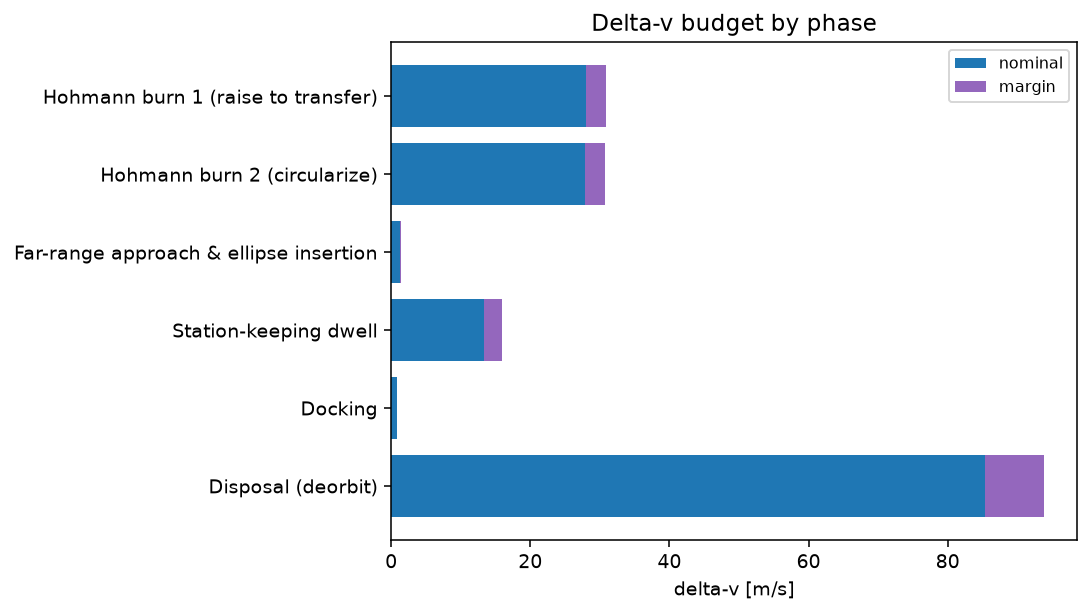
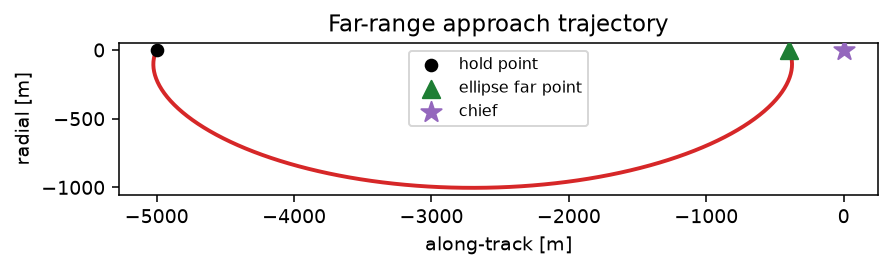

In [3]:
html = render_html(result)
Path("baseline_report.html").write_text(html, encoding="utf-8")
print(f"wrote baseline_report.html ({len(html)} bytes)")

try:
    render_pdf(html, "baseline_report.pdf")
    print("wrote baseline_report.pdf")
except Exception as exc:
    print(f"PDF export skipped: {exc}")

display(HTML(html))

## A scenario that passes: better relative navigation

`improved_nav_scenario.yaml` is identical to the baseline in every respect except one: the assumed relative-navigation uncertainty drops from 10 m to 3 m, standing in for a more precise sensor (a vision-based or lidar relative navigation system, say) rather than a coarser one. Nothing about the trajectory design or the propellant budget changes; only the input to the Monte Carlo check does.

verdict: FEASIBLE
Monte Carlo collision probability: 0.935% (threshold: 1.000%)



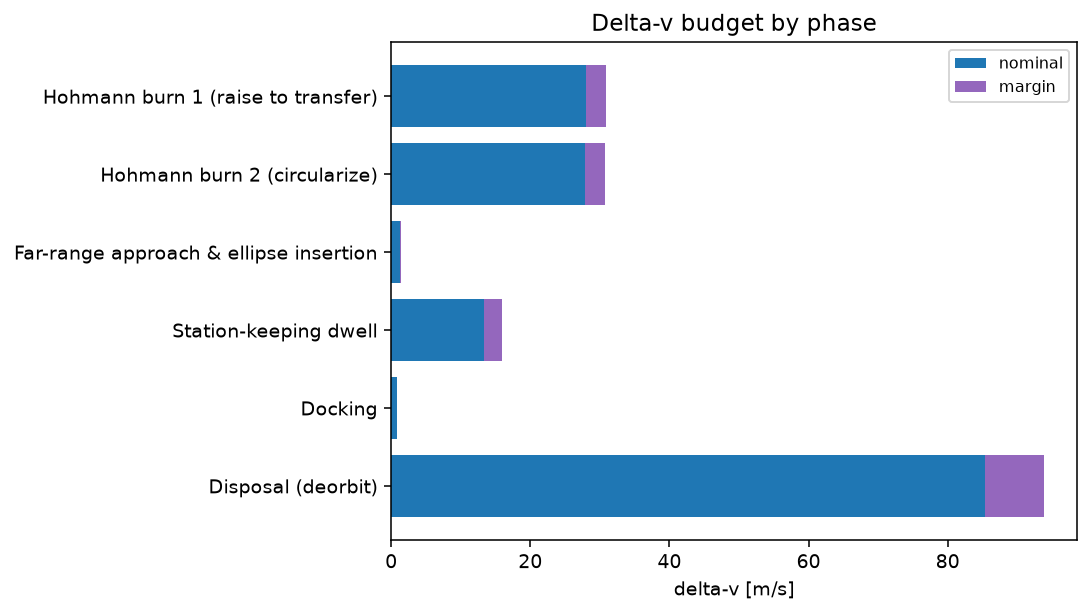
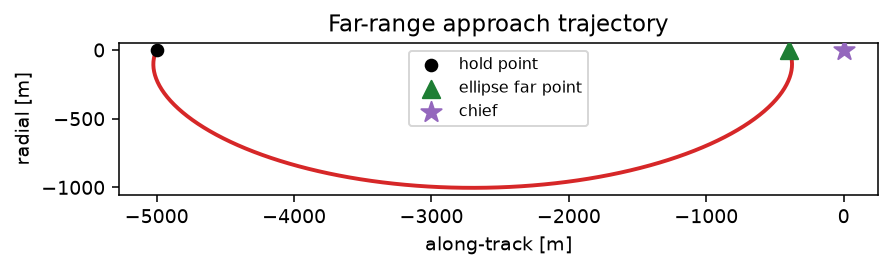

In [4]:
scenario_improved = load_scenario(SCENARIOS_DIR / "improved_nav_scenario.yaml")
result_improved = run_feasibility_analysis(scenario_improved)

print(f"verdict: {result_improved.verdict}")
print(f"Monte Carlo collision probability: {result_improved.collision_probability:.3%} "
      f"(threshold: {scenario_improved.verdict_thresholds.max_collision_probability:.3%})")

html_improved = render_html(result_improved)
Path("improved_nav_report.html").write_text(html_improved, encoding="utf-8")

try:
    render_pdf(html_improved, "improved_nav_report.pdf")
except Exception:
    pass

display(HTML(html_improved))

The same mission, the same budget, the same deterministic safety margins, but a tighter navigation assumption is enough to bring the collision probability under threshold and flip the verdict to feasible. This is exactly the kind of trade a real feasibility study needs to surface: not just whether a mission works, but which assumption it is most sensitive to, and by how much.

## From the screening to the full analysis

The screening above is fast because it avoids everything that takes time. It does not fly the approach, it has no sensors and no controllers, and it judges safety with a linear propagation that makes no corrections along the way. A mission that passes it deserves the complete analysis: the closed-loop simulation of the approach and docking, a Monte Carlo campaign with dispersed hardware, and the lighting of the docking port. `analyze_mission` judges the three together against explicit requirements, and `render_mission_report` writes the document.

The requirements used here are a probability of docking inside the contact limits of at least 0.90, demonstrated at 95 percent confidence, a velocity change of the approach of at most 8 m/s at the 99th percentile, and a final approach flown in favourable lighting.

In [5]:
import os

import numpy as np

from ios_mission_planner.constants import J2_EARTH, MU_EARTH, R_EARTH
from ios_mission_planner.illumination.lighting import port_lighting_timeline
from ios_mission_planner.illumination.sun import julian_date_from_datetime
from ios_mission_planner.report.mission_report import MissionRequirements, analyze_mission, render_mission_report
from ios_mission_planner.sim.config import SimulationConfig
from ios_mission_planner.sim.monte_carlo import Dispersions, run_monte_carlo
from ios_mission_planner.sim.simulator import simulate

WORKERS = max(1, (os.cpu_count() or 2) // 2)
requirements = MissionRequirements(min_success_probability=0.90, max_delta_v=8.0)


def full_analysis(name, config, n_runs=60):
    """Nominal run, Monte Carlo campaign and lighting of the port, judged together."""
    chief = config.chief
    nominal = simulate(config)
    campaign = run_monte_carlo(config, Dispersions(), n_runs=n_runs, first_seed=1, workers=WORKERS)
    lighting = port_lighting_timeline(
        R_EARTH + chief.altitude_km, np.deg2rad(chief.inclination_deg), np.deg2rad(chief.raan_deg),
        np.deg2rad(chief.argument_of_latitude_deg), julian_date_from_datetime(config.epoch),
        config.max_duration, 10.0, MU_EARTH, J2_EARTH, R_EARTH, port_normal_lvlh=chief.port_axis,
    )
    return analyze_mission(name, nominal, campaign, lighting, requirements)


def summarize(analysis):
    campaign = analysis.campaign
    low, high = campaign.success_interval(requirements.confidence)
    start, end = analysis.final_approach
    print(f"verdict: {analysis.verdict}")
    for issue in analysis.issues:
        print(f"  issue:  {issue}")
    for caveat in analysis.caveats:
        print(f"  caveat: {caveat}")
    print(f"nominal run: {analysis.nominal.outcome}, {analysis.nominal.total_delta_v:.2f} m/s, "
          f"final approach from {start / 60:.1f} to {end / 60:.1f} min, in favourable lighting: {analysis.final_approach_lit}")
    print(f"campaign: {int(campaign.success.sum())} of {campaign.n_runs} docked, interval {low:.3f} to {high:.3f}; "
          f"delta-v at the 99th percentile {np.percentile(campaign.delta_v, 99):.2f} m/s")


analysis = full_analysis("Docking of the reference mission", SimulationConfig(seed=1))
summarize(analysis)

verdict: FEASIBLE WITH CAVEATS
  caveat: The final approach of the nominal run is not flown in favourable lighting; it has to be held at the last hold point until a window opens. The next window long enough opens 2 min later.
nominal run: docked, 6.06 m/s, final approach from 91.2 to 96.0 min, in favourable lighting: False
campaign: 60 of 60 docked, interval 0.940 to 1.000; delta-v at the 99th percentile 6.52 m/s


The verdict is feasible with caveats, and the caveat is not about the docking. The nominal run docks for 6.06 m/s. All 60 runs of the campaign dock, which puts the probability of success between 0.94 and 1 at 95 percent confidence, above the 0.90 required, and the velocity change at the 99th percentile, 6.52 m/s, is within the 8 m/s available. What the analysis flags is the timing: the final approach of the nominal run starts at 91.2 minutes, two minutes before the lighting window of the port opens, so its first part would be flown with the Sun still grazing the port.

The size of the campaign matters for the wording of the verdict. Sixty runs without a failure demonstrate 0.94. Had the requirement been 0.95, the same campaign would have produced a caveat saying that it is too small to demonstrate it, which is a different statement from saying that the mission fails.

verdict: FEASIBLE
nominal run: docked, 6.08 m/s, final approach from 93.3 to 98.1 min, in favourable lighting: True
campaign: 60 of 60 docked, interval 0.940 to 1.000; delta-v at the 99th percentile 6.54 m/s



wrote docking_mission_report.html (369172 bytes)


wrote docking_mission_report.pdf


"Probability of a docking inside the contact limits, demonstrated at 95 % confidence",at least 0.900
"Velocity change of the approach, 99th percentile",at most 8.00 m/s
Final approach in favourable lighting,required
Chief altitude,500 km
Chief inclination,51.6 deg
Deputy mass,160 kg
Thrust per axis,2.0 N
Minimum impulse bit,0.040 N s
Specific impulse,220 s
"Hold points, port to port","5000, 500, 20 m"
Approach corridor half-angle,10 deg

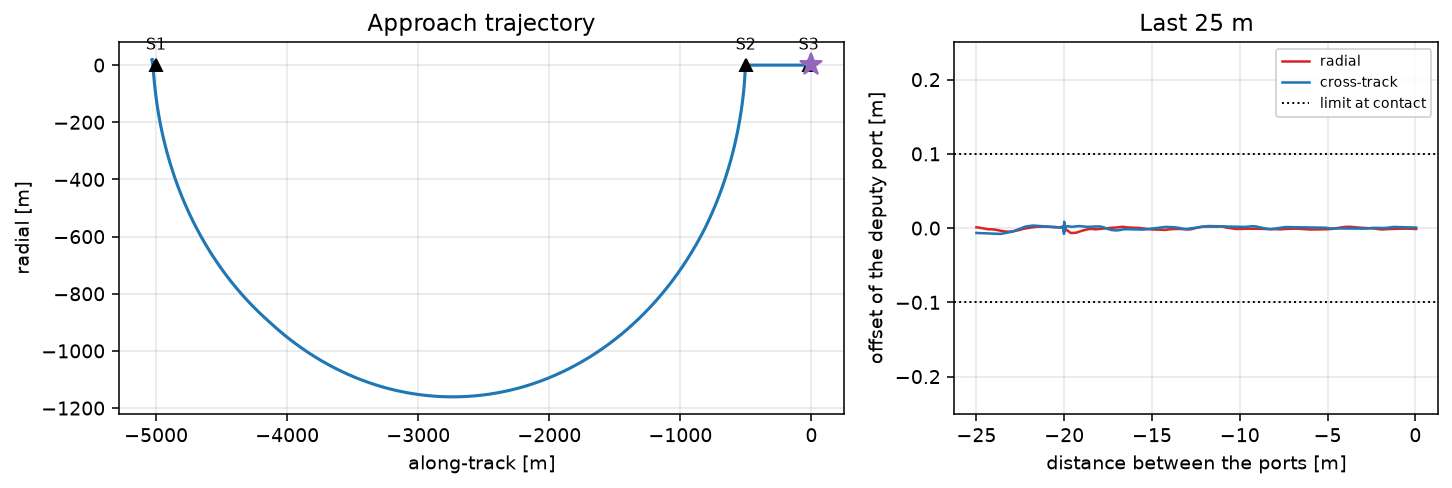
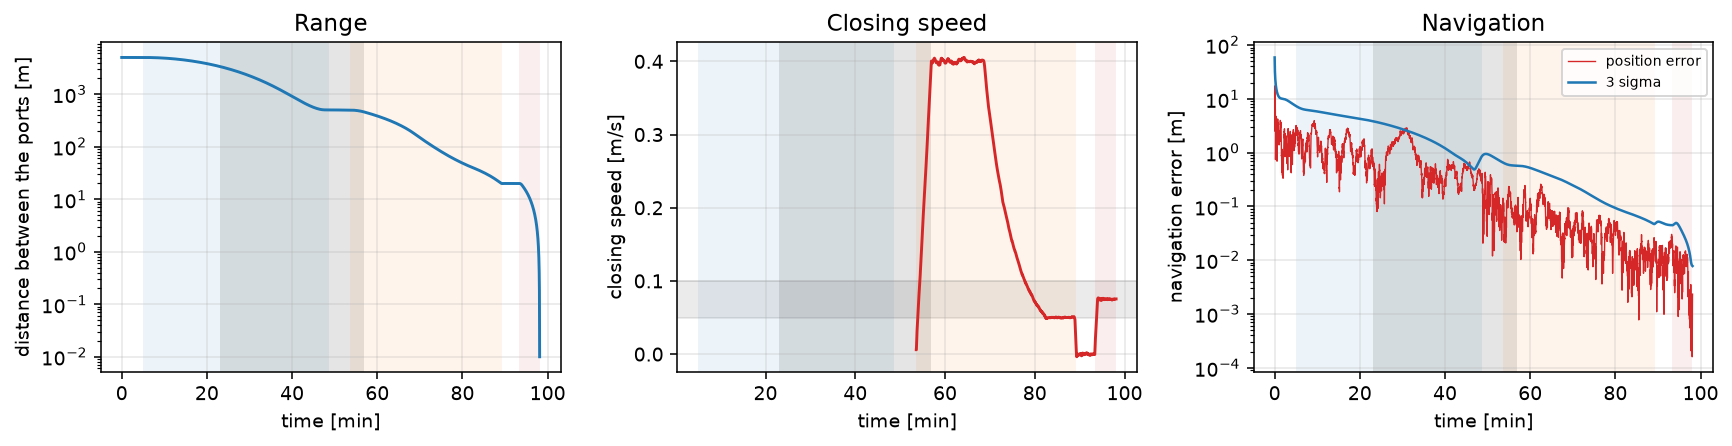
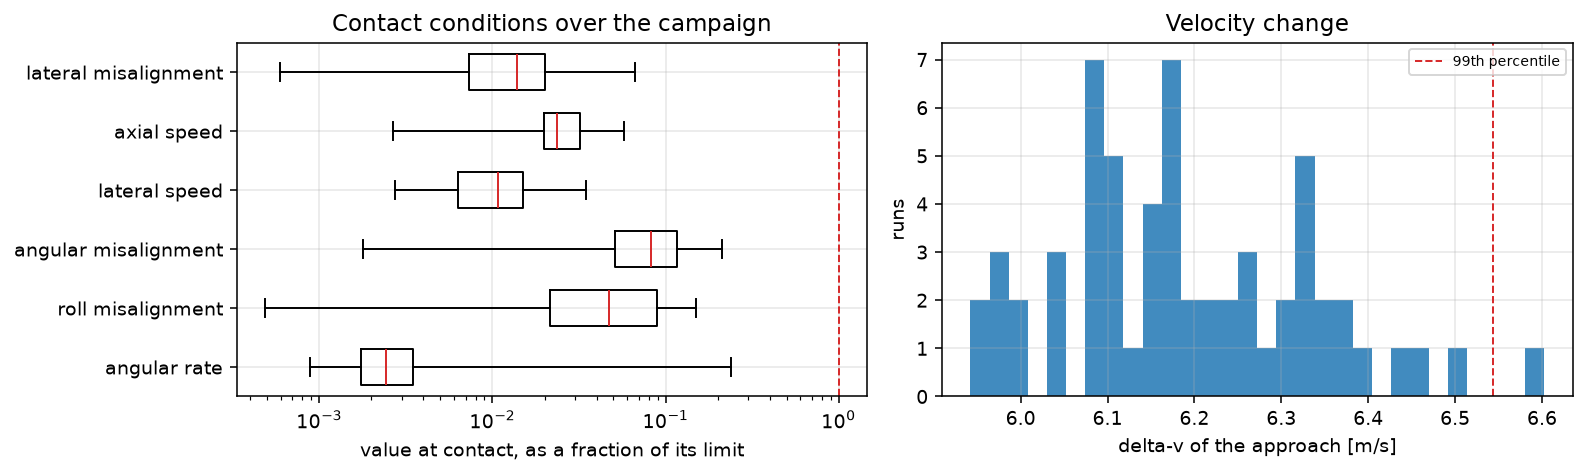
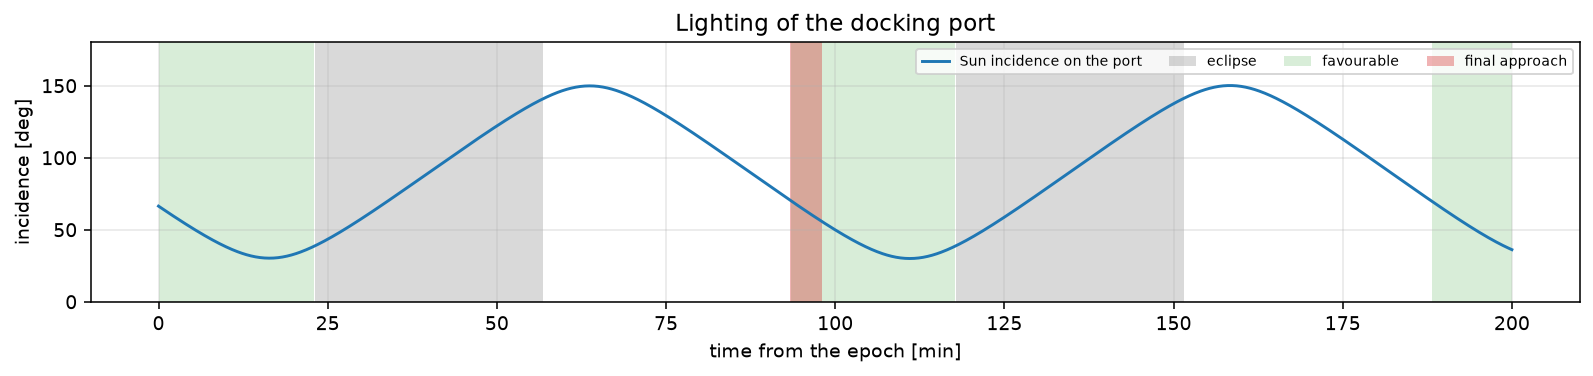

In [6]:
gated = SimulationConfig(seed=1)
gated.guidance.lighting_gate = True

analysis_gated = full_analysis("Docking of the reference mission", gated)
summarize(analysis_gated)

html_mission = render_mission_report(analysis_gated)
Path("docking_mission_report.html").write_text(html_mission, encoding="utf-8")
print(f"\nwrote docking_mission_report.html ({len(html_mission)} bytes)")

try:
    render_pdf(html_mission, "docking_mission_report.pdf")
    print("wrote docking_mission_report.pdf")
except Exception as exc:
    print(f"PDF export skipped: {exc}")

display(HTML(html_mission))

With the go/no-go on lighting the deputy waits two more minutes at the last hold point, the final approach falls entirely inside the window, and the verdict is feasible with nothing to flag. The wait costs 0.02 m/s on the nominal run.

The document above is what this analysis produces: the verdict, the requirements, the scenario, the timeline and the trajectory of the nominal run, the conditions at contact, the statistics of the campaign and the lighting windows with the final approach among them. It is written to `docking_mission_report.html`, a single file with its figures embedded, and to PDF.

The two reports of this notebook answer different questions, and neither replaces the other. The screening covers the whole mission, from the parking orbit to the disposal, with closed-form models and a linear, uncorrected propagation of the uncertainty. The full analysis covers the approach and the docking, flown in closed loop by the navigation and the controllers of the deputy.

## Summary

This turns the tools built so far into a feasibility report that a declarative scenario file produces automatically, by orchestrating the dynamics, safety, and budget tools built in every earlier chapter of this book, rather than by hand-wiring a new notebook for every mission. The pipeline stays deliberately simple in one respect worth stating plainly: every delta-v comes from closed-form methods, not from a fresh nonlinear re-flight of the mission the way `mission_budget.ipynb` itself does, which is why the far-range hop and the ellipse insertion collapse into a single budget line here instead of the two separate, slightly different burns that notebook flies. That is an honest simplification for a tool meant to turn a scenario around in seconds, not a hidden one: the pipeline flags it explicitly whenever it is worth noticing.

The second half of the notebook takes the approach and the docking through the full analysis. `analyze_mission` judges a closed-loop simulation, a Monte Carlo campaign and the lighting of the port against explicit requirements, and `render_mission_report` writes the document. For the reference mission the docking succeeds in every run of a 60-run campaign, and the only finding is the timing of the final approach with respect to the light, which a go/no-go at the last hold point resolves.

What this does not do yet is pick scenarios: nothing here searches over mission parameters for one that passes, or explains why the input it was given has whatever margin it has beyond the explicit checks already built. Turning this from a report generator into a design tool, one that suggests what to change rather than just saying yes or no, is a natural next step this notebook does not take.